<a href="https://colab.research.google.com/github/oliveiracatarina/BigData_DataScience_FinalProject/blob/main/Assignment2_Catarina_de_Oliveira_Souza.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Load the dataset

In [17]:
import pandas as pd

df = pd.read_csv('/Mall_Customers.csv')

print("Dataset loaded successfully")
print("Shape (rows, columns):", df.shape)
df.head()

Dataset loaded successfully
Shape (rows, columns): (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. Dataset structure

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


## 3. Data quality checks

In [19]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicated rows:", df.duplicated().sum())
print("Duplicated CustomerID:", df['CustomerID'].duplicated().sum())

print("\nGender categories:")
print(df['Gender'].value_counts())

Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicated rows: 0
Duplicated CustomerID: 0

Gender categories:
Gender
Female    112
Male       88
Name: count, dtype: int64


## 4. Descriptive statistics

In [20]:
df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].describe().round(2)

,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


## 5. Exploratory plots (distributions)

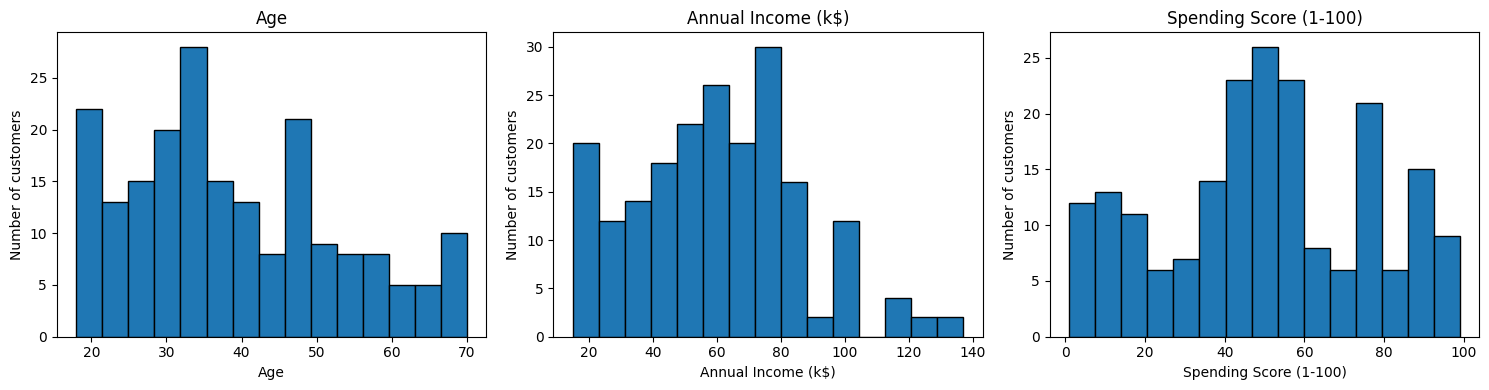

In [21]:
import matplotlib.pyplot as plt

features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features):
    ax.hist(df[col], bins=15, edgecolor='black')
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Number of customers')

plt.tight_layout()
plt.show()

## 6. Exploratory plot (Income vs Spending Score)

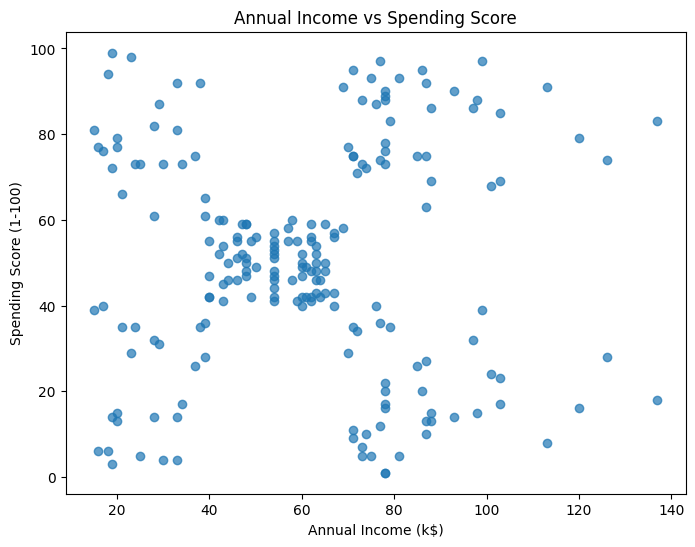

In [22]:
plt.figure(figsize=(8, 6))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], alpha=0.7)
plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

## 7. Correlation between variables

In [23]:
df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].corr().round(2)

,Age,Annual Income (k$),Spending Score (1-100)
Age,1.00,-0.01,-0.33
Annual Income (k$),-0.01,1.00,0.01
Spending Score (1-100),-0.33,0.01,1.00


## 8. Feature selection and standardization

In [24]:
from sklearn.preprocessing import StandardScaler

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=['Income_scaled', 'Spending_scaled'])

print("Selected features:", list(X.columns))
print("Shape of scaled data:", X_scaled.shape)
print("\nMean after scaling (should be about 0):")
print(X_scaled_df.mean().round(2))
print("\nStd after scaling (should be about 1):")
print(X_scaled_df.std(ddof=0).round(2))

X_scaled_df.head()

Selected features: ['Annual Income (k$)', 'Spending Score (1-100)']
Shape of scaled data: (200, 2)

Mean after scaling (should be about 0):
Income_scaled     -0.0
Spending_scaled   -0.0
dtype: float64

Std after scaling (should be about 1):
Income_scaled      1.0
Spending_scaled    1.0
dtype: float64


,Income_scaled,Spending_scaled
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


## 9. Elbow Method

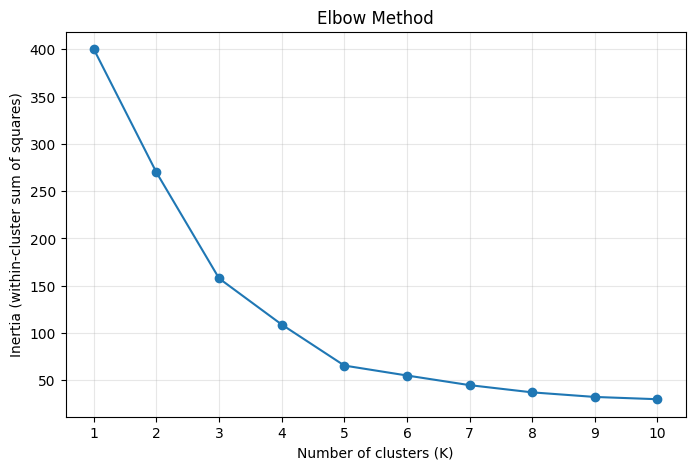

,K,Inertia
0,1,400.00
1,2,269.69
2,3,157.70
3,4,108.92
4,5,65.57
5,6,55.06
6,7,44.86
7,8,37.23
8,9,32.39
9,10,29.98


In [25]:
from sklearn.cluster import KMeans

k_values = range(1, 11)
inertia_values = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

elbow_df = pd.DataFrame({'K': list(k_values),
                         'Inertia': [round(i, 2) for i in inertia_values]})
elbow_df

## 10. Silhouette Score

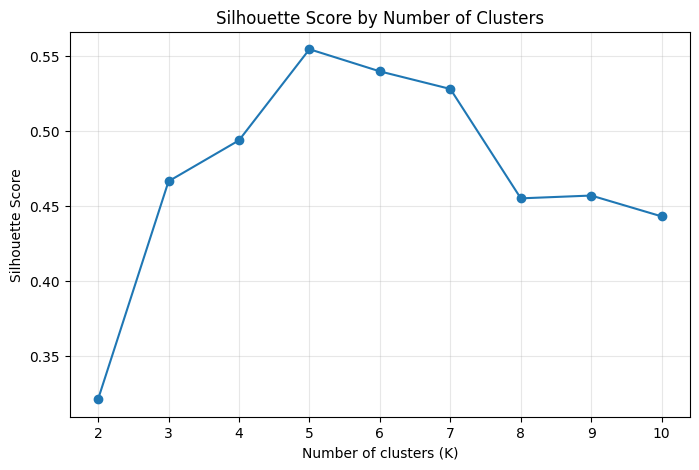

,K,Silhouette Score
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


In [26]:
from sklearn.metrics import silhouette_score

k_range = range(2, 11)
silhouette_values = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_values, marker='o')
plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(k_range))
plt.grid(True, alpha=0.3)
plt.show()

silhouette_df = pd.DataFrame({'K': list(k_range),
                              'Silhouette Score': [round(s, 4) for s in silhouette_values]})
silhouette_df

## 11. Final K-Means model (K = 5)

In [27]:
final_k = 5

kmeans_final = KMeans(n_clusters=final_k, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

print("Final model trained with K =", final_k)
print("Silhouette Score:", round(silhouette_score(X_scaled, df['Cluster']), 4))
print("Inertia:", round(kmeans_final.inertia_, 2))

cluster_counts = df['Cluster'].value_counts().sort_index()
cluster_summary = pd.DataFrame({
    'Customers': cluster_counts,
    'Percentage (%)': (cluster_counts / len(df) * 100).round(1)
})
print("\nCustomers per cluster:")
print(cluster_summary)

df.head()

Final model trained with K = 5
Silhouette Score: 0.5547
Inertia: 65.57

Customers per cluster:
         Customers  Percentage (%)
Cluster                           
0               81            40.5
1               39            19.5
2               22            11.0
3               35            17.5
4               23            11.5


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


## 12. Cluster profiling

In [28]:
profile_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

cluster_profile = df.groupby('Cluster')[profile_cols].mean().round(2)
cluster_profile.insert(0, 'Customers', df['Cluster'].value_counts().sort_index())

gender_pct = (pd.crosstab(df['Cluster'], df['Gender'], normalize='index') * 100).round(1)
cluster_profile['Female (%)'] = gender_pct['Female']
cluster_profile['Male (%)'] = gender_pct['Male']

cluster_profile

,Customers,Age,Annual Income (k$),Spending Score (1-100),Female (%),Male (%)
Cluster,,,,,,
0,81,42.72,55.30,49.52,59.3,40.7
1,39,32.69,86.54,82.13,53.8,46.2
2,22,25.27,25.73,79.36,59.1,40.9
3,35,41.11,88.20,17.11,45.7,54.3
4,23,45.22,26.30,20.91,60.9,39.1


## 13. Cluster visualization

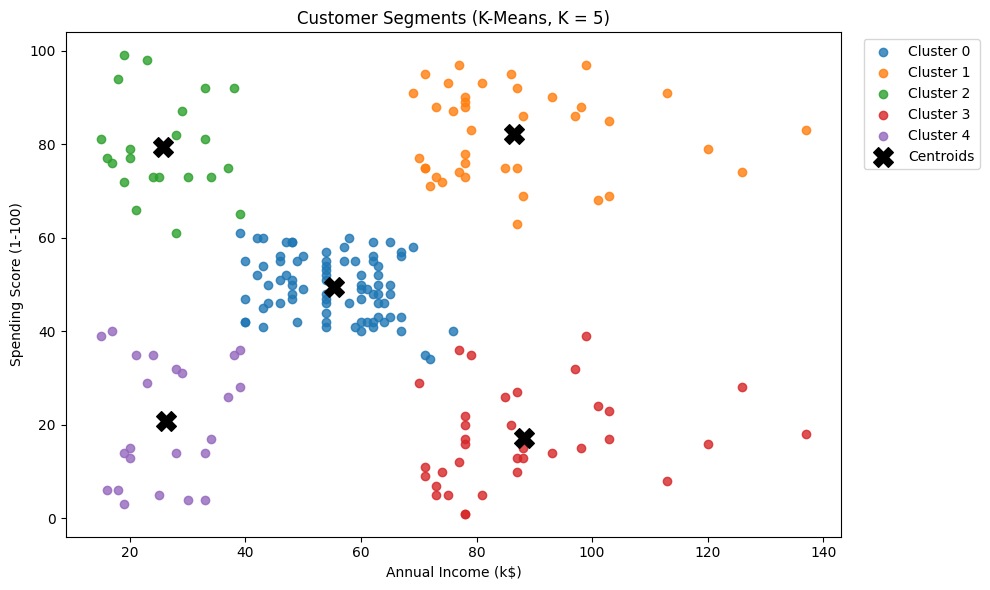

In [29]:
centroids = scaler.inverse_transform(kmeans_final.cluster_centers_)

plt.figure(figsize=(10, 6))

for c in sorted(df['Cluster'].unique()):
    subset = df[df['Cluster'] == c]
    plt.scatter(subset['Annual Income (k$)'], subset['Spending Score (1-100)'],
                label=f'Cluster {c}', alpha=0.8)

plt.scatter(centroids[:, 0], centroids[:, 1], c='black', marker='X', s=200, label='Centroids')

plt.title('Customer Segments (K-Means, K = 5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 14. Export clustered dataset

In [30]:
df.to_csv('Mall_Customers_clustered.csv', index=False)

from google.colab import files
files.download('Mall_Customers_clustered.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>